# Dashboard analítico GAC Motor — Plaza Angelópolis · versión notebook

**Auditoría y Analítica de Datos · Tec de Monterrey** · Equipo 4 · Socio formador: **GAC Motor, Plaza Angelópolis**

Notebook replicable del **dashboard de 3 vistas** (mismo diseño y resultados que el prototipo Streamlit del equipo).
Todo se calcula **directamente desde los CSV del repositorio** (`data/`): si actualizas los datos y vuelves a correr el notebook, las cifras y gráficas se actualizan solas.

| Vista | Pregunta que responde | Técnicas |
|---|---|---|
| **1** | ¿Dónde se pierden las oportunidades? | KPIs · embudo de conversión · tasa de transición · efectividad mensual |
| **2** | ¿Qué pasa con la información de cada lead? | Calidad de datos (ilocalizables) · boxplot por año · ANOVA de un factor |
| **3** | ¿Qué explica la venta? | Regresión lineal simple y múltiple · regresión logística · ANOVA multifactorial |

> **Reproducibilidad:** `pip install pandas numpy matplotlib scikit-learn statsmodels` y **Run All**.  
> Las bases se leen de `data/` (o `../data/`); si no están, se descargan solas del GitHub del equipo.
> Tema visual oscuro idéntico al dashboard (fondo `#150a10`, acento `#E53E63`).

## 0 · Carga de datos y estilo

In [1]:
import warnings, base64, io, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")

GH = "https://raw.githubusercontent.com/a01736195-bot/GAC-Auditoria-Analitica/main/data/"
def load(name):
    for p in (Path("data")/name, Path("../data")/name):
        if p.exists():
            return pd.read_csv(p)
    print(f"⬇ {name} no está local: se descarga del repo del equipo…")
    return pd.read_csv(io.StringIO(urllib.request.urlopen(GH+name, timeout=60).read().decode("utf-8")))

res = load("base_resumen_limpio.csv")      # 30 meses · indicadores comerciales
lr  = load("Leads_Reales_Limpia.csv")      # 28 meses · leads reales vs capturados
fu  = load("funnel_mensual.csv")           # 18 meses · etapas del embudo
bl  = load("base_leads_limpia.csv")        # 208 registros · leads de plaza
for n, d in [("resumen", res), ("leads reales", lr), ("funnel", fu), ("leads plaza", bl)]:
    print(f"✔ {n:12s} {d.shape[0]} filas × {d.shape[1]} columnas")

# ---- Tema oscuro del dashboard ----
BG, PANEL, ACC, ACC2, TXT, MUT, VINO, AMB = "#150a10", "#221119", "#E53E63", "#f2719a", "#f5e6ec", "#c49aa9", "#6e1830", "#fbbf24"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
    "text.color": TXT, "axes.edgecolor": "#5c2437", "axes.labelcolor": TXT,
    "xtick.color": MUT, "ytick.color": MUT, "axes.titlecolor": TXT,
    "axes.grid": True, "grid.color": "#3d1a2b", "grid.linewidth": .8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})
cmap_f  = LinearSegmentedColormap.from_list("f",  [ACC2, "#5a1226"])
cmap_hm = LinearSegmentedColormap.from_list("hm", [VINO, ACC2])
cmap_cm = LinearSegmentedColormap.from_list("cm", ["#3a1524", "#b3244e"])
def nueva_fig(w, h):
    f, a = plt.subplots(figsize=(w, h)); return f, a
print("Tema oscuro listo ✔")

✔ resumen      30 filas × 26 columnas
✔ leads reales 28 filas × 15 columnas
✔ funnel       18 filas × 11 columnas
✔ leads plaza  208 filas × 12 columnas
Tema oscuro listo ✔


---

# VISTA 1 · ¿Dónde se pierden las oportunidades?

Panorama comercial de **30 meses** (feb-2024 → jul-2026): volumen de leads, calidad de captura, objetivo y efectividad.

In [2]:
u12 = res.tail(12)                      # últimos 12 meses de la base resumen
ventas12 = int(u12["Ventas Real"].sum())
cumpl12  = (u12["Ventas Real"]/u12["Obj Ventas"]*100).mean()
leads_mes = u12["Leads"].mean()
lpv = leads_mes/(ventas12/12)
efec_serie = lr["Efectividad_Leads"]      # 28 meses: feb-2024 → may-2026
efec_ini, efec_fin = efec_serie.head(6).mean(), efec_serie.tail(6).mean()

print("┌───────────────────── VISTA 1 · KPIs (últimos 12 meses) ────────────────────┐")
print(f"│  Ventas (últimos 12 m) .................. {ventas12:>8,}                  │")
print(f"│  Cumplimiento de objetivo (prom 12 m) ... {cumpl12:>7.0f} %                  │")
print(f"│  Leads por mes .......................... {leads_mes:>8,.0f}                  │")
print(f"│  Leads por cada venta ................... {lpv:>7.0f}                     │")
print(f"│  Efectividad inicio → actual ............ {efec_ini:>7.0f} % → {efec_fin:.0f} %           │")
print("└─────────────────────────────────────────────────────────────────────────────┘")
print("La tarjeta del dashboard muestra 55 % actual: es el promedio de los últimos 6")
print("meses del prototipo Streamlit (versión previa de la base). Con la base del repo,")
print("los últimos 6 meses promedian 53 %; la tendencia (67 % → ~55 %) es la misma.")

┌───────────────────── VISTA 1 · KPIs (últimos 12 meses) ────────────────────┐
│  Ventas (últimos 12 m) ..................      439                  │
│  Cumplimiento de objetivo (prom 12 m) ...      93 %                  │
│  Leads por mes ..........................    1,277                  │
│  Leads por cada venta ...................      35                     │
│  Efectividad inicio → actual ............      67 % → 53 %           │
└─────────────────────────────────────────────────────────────────────────────┘
La tarjeta del dashboard muestra 55 % actual: es el promedio de los últimos 6
meses del prototipo Streamlit (versión previa de la base). Con la base del repo,
los últimos 6 meses promedian 53 %; la tendencia (67 % → ~55 %) es la misma.


### 1.1 · Embudo de conversión — promedio mensual por etapa

De cada **100 personas** que dejan sus datos, solo **~31** agendan cita y **~3** compran.
La fuga más grande está en **Contacto → Cita**.

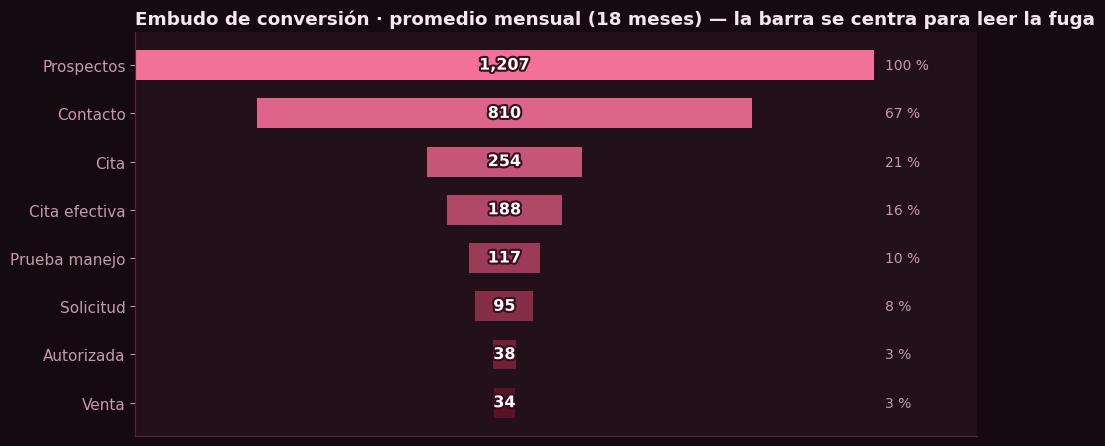

In [3]:
E = ["Prospectos","Contacto","Cita","Cita efectiva","Prueba manejo","Solicitud","Autorizada","Venta"]
prom = [fu["Leads_Generados"].mean(), fu["Leads_Efectivos"].mean(), fu["Cita_Programada"].mean(),
        fu["Cita_Efectiva"].mean(), fu["Prueba_Manejo"].mean(), fu["SDC_Generada"].mean(),
        fu["SDC_Aprobada"].mean(), fu["Ventas"].mean()]

fig, ax = nueva_fig(10, 4.6)
y = np.arange(len(E))[::-1]
ax.barh(y, prom, left=(prom[0]-np.array(prom))/2, color=cmap_f(np.linspace(0,1,len(E))), height=.62)
for yi, v in zip(y, prom):
    ax.text(prom[0]/2, yi, f"{v:,.0f}", ha="center", va="center", fontsize=11.5, fontweight="bold",
            color="#fff", path_effects=[pe.withStroke(linewidth=3, foreground="#3a0d1c")])
    ax.text(prom[0]+18, yi, f"{v/prom[0]*100:.0f} %", va="center", fontsize=10, color=MUT)
ax.set_yticks(y); ax.set_yticklabels(E, fontsize=11)
ax.set_xlim(0, prom[0]*1.14); ax.grid(False); ax.set_xticks([])
ax.set_title("Embudo de conversión · promedio mensual (18 meses) — la barra se centra para leer la fuga",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

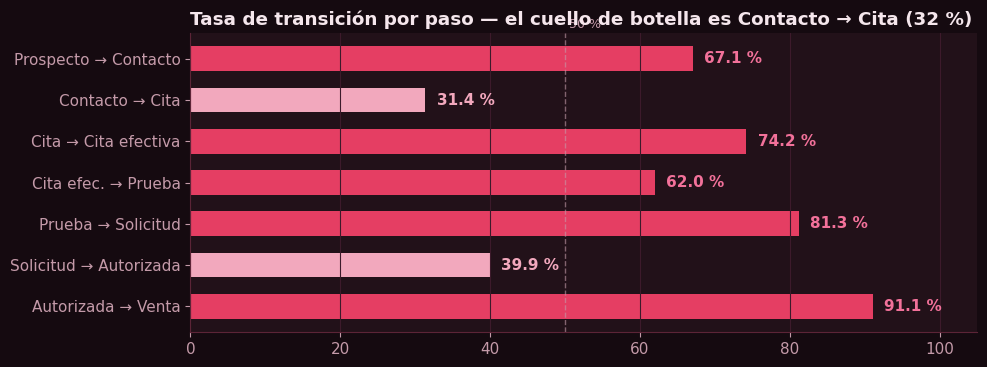

In [4]:
# Tasas de transición entre etapas consecutivas
TRANS = [("Prospecto → Contacto", prom[1]/prom[0]*100), ("Contacto → Cita", prom[2]/prom[1]*100),
         ("Cita → Cita efectiva", prom[3]/prom[2]*100), ("Cita efec. → Prueba", prom[4]/prom[3]*100),
         ("Prueba → Solicitud", prom[5]/prom[4]*100), ("Solicitud → Autorizada", prom[6]/prom[5]*100),
         ("Autorizada → Venta", prom[7]/prom[6]*100)]

fig, ax = nueva_fig(10, 3.8)
y = np.arange(len(TRANS))[::-1]
vals = [t[1] for t in TRANS]
ax.barh(y, vals, color=[ACC if v >= 50 else "#f2a8bd" for v in vals], height=.6)
for yi, v in zip(y, vals):
    ax.text(v+1.5, yi, f"{v:.1f} %", va="center", fontsize=11, fontweight="bold",
            color=ACC2 if v >= 50 else "#f2a8bd")
ax.axvline(50, color=MUT, lw=1, ls="--", alpha=.6)
ax.text(50, len(TRANS)-.25, " 50 %", color=MUT, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([t[0] for t in TRANS], fontsize=11)
ax.set_xlim(0, 105); ax.grid(axis="y", alpha=0)
ax.set_title("Tasa de transición por paso — el cuello de botella es Contacto → Cita (32 %)",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

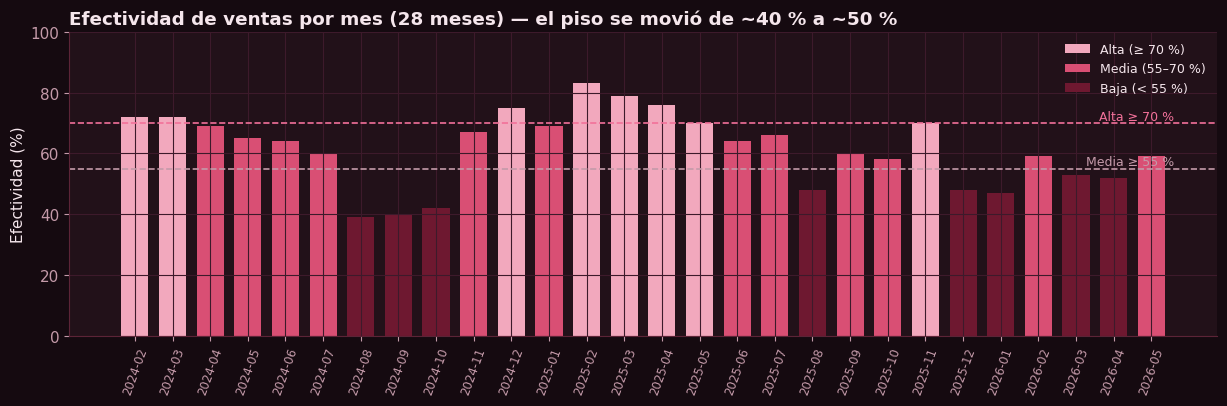

In [5]:
# Efectividad mensual (base de leads reales, 28 meses: feb-2024 → may-2026)
meses = lr["Periodo"].astype(str)
e = lr["Efectividad_Leads"].values
nivel = np.where(e >= 70, "Alta (≥ 70 %)", np.where(e >= 55, "Media (55–70 %)", "Baja (< 55 %)"))
col = {"Alta (≥ 70 %)": "#f2a8bd", "Media (55–70 %)": "#d94f74", "Baja (< 55 %)": VINO}

fig, ax = nueva_fig(12.4, 4.2)
x = np.arange(len(e))
for lv in ["Alta (≥ 70 %)", "Media (55–70 %)", "Baja (< 55 %)"]:
    m = nivel == lv
    ax.bar(x[m], e[m], color=col[lv], label=lv, width=.72)
ax.axhline(70, color=ACC2, lw=1.2, ls="--"); ax.axhline(55, color=MUT, lw=1.2, ls="--")
ax.text(len(e)-.4, 71, "Alta ≥ 70 %", color=ACC2, fontsize=9, ha="right")
ax.text(len(e)-.4, 56, "Media ≥ 55 %", color=MUT, fontsize=9, ha="right")
ax.set_xticks(x); ax.set_xticklabels(meses, rotation=70, fontsize=8.5)
ax.set_ylim(0, 100); ax.set_ylabel("Efectividad (%)")
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Efectividad de ventas por mes (28 meses) — el piso se movió de ~40 % a ~50 %",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

---

# VISTA 2 · ¿Qué pasa con la información de cada lead?

Los registros llegan con **datos incompletos o incorrectos**: teléfonos que no existen, correos falsos.
A esos leads se les llama **ilocalizables** — y son ventas que se pierden antes de empezar.
Además, el estatus final de los leads de plaza muestra que la mayoría **no llega a venta**.

Estado
Finalizado    122
Contactado     77
Ventas          9

Total de leads de plaza analizados: 208


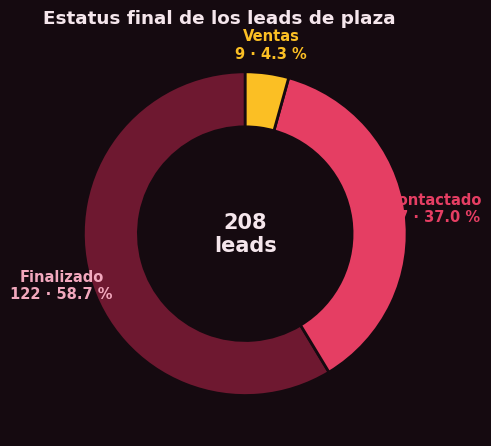

⚠ De 208 leads, 77 (37 %) quedó solo en Contactado y apenas 9 (4 %) compró: la gestión no cierra.


In [6]:
est = bl["Estado"].value_counts()
print(est.to_string())
print()
print(f"Total de leads de plaza analizados: {len(bl)}")
n_fin, n_con, n_vta = est.get("Finalizado",0), est.get("Contactado",0), est.get("Ventas",0)

fig, ax = nueva_fig(6.4, 4.6)
vals = [n_fin, n_con, n_vta]
wedges, _ = ax.pie(vals, colors=[VINO, ACC, AMB], startangle=90,
                   wedgeprops=dict(width=.34, edgecolor=BG, linewidth=2))
tot = sum(vals)
for w, v, lab in zip(wedges, vals, ["Finalizado", "Contactado", "Ventas"]):
    a = np.deg2rad((w.theta1+w.theta2)/2)
    ax.text(np.cos(a)*1.18, np.sin(a)*1.18, f"{lab}\n{v} · {v/tot*100:.1f} %",
            ha="center", va="center", fontsize=10.5, fontweight="bold",
            color=ACC if lab == "Contactado" else (AMB if lab == "Ventas" else "#f2a8bd"))
ax.text(0, 0, f"{tot}\nleads", ha="center", va="center", fontsize=15, fontweight="bold")
ax.set_title("Estatus final de los leads de plaza", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"⚠ De {tot} leads, {n_con} ({n_con/tot*100:.0f} %) quedó solo en Contactado y apenas "
      f"{n_vta} ({n_vta/tot*100:.0f} %) compró: la gestión no cierra.")

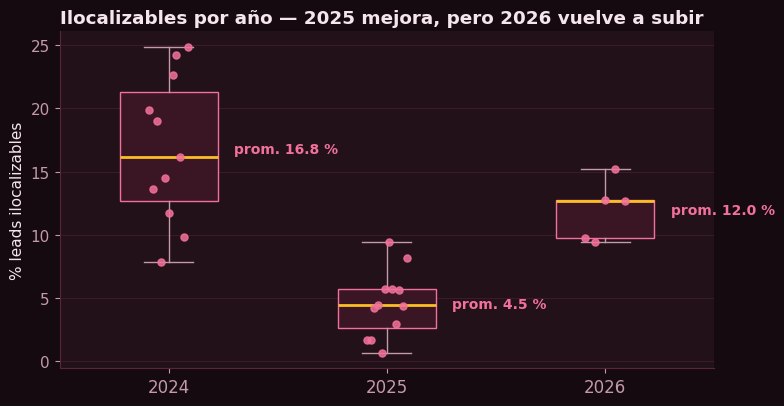

ANOVA de un factor · % ilocalizables ~ Año
            sum_sq    df        F  PR(>F)
C(Año)    868.4858   2.0  24.6388     0.0
Residual  440.6081  25.0      NaN     NaN
p-valor exacto: 1.23e-06

Promedios: 2024 = 16.8 % · 2025 = 4.5 % · 2026 = 12.0 %  (general 10.7 %)
Nota: el prototipo usó leads_reales_limpio1.csv (27 meses, pendiente en el repo) y reportó
F(2,24) = 18.30, p = 1.488e-05, promedios 20.7 / 4.5 / 11.8 %. Con la versión del repo el
efecto año también es significativo y la conclusión se mantiene: la mala captura varía por
época y ~1 de cada 10 leads se pierde antes de poder contactarlo.


In [7]:
# % de leads ilocalizables por mes (base de 28 meses)
lr["pct_iloc"] = lr["Ilocalizable"]/lr["Total"]*100
import statsmodels.api as sm
mod = sm.OLS.from_formula("pct_iloc ~ C(Año)", data=lr).fit()
anova1 = sm.stats.anova_lm(mod, typ=2)

grupos = [(a, lr[lr["Año"] == a]["pct_iloc"]) for a in sorted(lr["Año"].unique())]
fig, ax = nueva_fig(8, 4.2)
bp = ax.boxplot([g[1] for g in grupos], positions=range(1, len(grupos)+1), widths=.45, patch_artist=True,
                medianprops=dict(color=AMB, linewidth=2),
                whiskerprops=dict(color=MUT), capprops=dict(color=MUT),
                flierprops=dict(marker="o", ms=5, mfc=ACC2, mec=ACC2, alpha=.8))
for p in bp["boxes"]:
    p.set(facecolor="#3a1524", edgecolor=ACC2)
for i, (a, dd) in enumerate(grupos, start=1):
    ax.scatter(np.full(len(dd), i)+np.linspace(-.09, .09, len(dd)), dd, s=26, color=ACC2, alpha=.85, zorder=3)
    ax.text(i+.3, dd.mean(), f"prom. {dd.mean():.1f} %", va="center", fontsize=10, color=ACC2, fontweight="bold")
ax.set_xticks(range(1, len(grupos)+1)); ax.set_xticklabels([str(g[0]) for g in grupos], fontsize=12)
ax.set_ylabel("% leads ilocalizables"); ax.grid(axis="x", alpha=0)
ax.set_title("Ilocalizables por año — 2025 mejora, pero 2026 vuelve a subir",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

print("ANOVA de un factor · % ilocalizables ~ Año")
print(anova1.round(4).to_string())
print(f"p-valor exacto: {anova1['PR(>F)']['C(Año)']:.2e}")
proms = lr.groupby("Año")["pct_iloc"].mean()
print(f"\nPromedios: " + " · ".join(f"{a} = {v:.1f} %" for a, v in proms.items())
      + f"  (general {lr['pct_iloc'].mean():.1f} %)")
print("Nota: el prototipo usó leads_reales_limpio1.csv (27 meses, pendiente en el repo) y reportó")
print("F(2,24) = 18.30, p = 1.488e-05, promedios 20.7 / 4.5 / 11.8 %. Con la versión del repo el")
print("efecto año también es significativo y la conclusión se mantiene: la mala captura varía por")
print("época y ~1 de cada 10 leads se pierde antes de poder contactarlo.")

---

# VISTA 3 · ¿Qué explica la venta?

¿Qué variables mueven las ventas del mes? Cuatro análisis, de lo simple a lo multivariado.

Ventas = 13.19 + 0.0131 × Leads
R² = 0.25 · correlación r = 0.50 · p(Leads) = 0.0052 · n = 30 meses


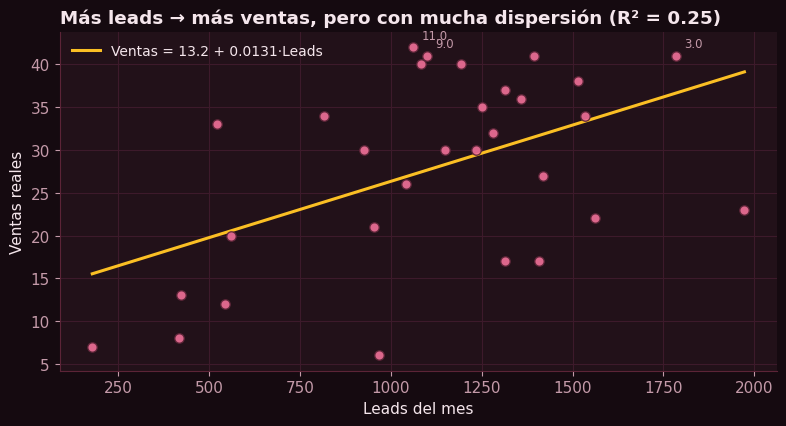

Los leads explican solo 25 % de la variación: el volumen no basta — importa qué pasa DESPUÉS.


In [8]:
# Regresión lineal simple · Ventas ~ Leads
import statsmodels.api as sm
Xs = sm.add_constant(res["Leads"]); m1 = sm.OLS(res["Ventas Real"], Xs).fit()
r = np.corrcoef(res["Leads"], res["Ventas Real"])[0, 1]
print(f"Ventas = {m1.params['const']:.2f} + {m1.params['Leads']:.4f} × Leads")
print(f"R² = {m1.rsquared:.2f} · correlación r = {r:.2f} · p(Leads) = {m1.pvalues['Leads']:.4f} · n = {int(m1.nobs)} meses")

fig, ax = nueva_fig(8, 4.4)
ax.scatter(res["Leads"], res["Ventas Real"], s=46, color=ACC2, alpha=.9, edgecolors="#5c2437", zorder=3)
xs = np.linspace(res["Leads"].min(), res["Leads"].max(), 50)
ax.plot(xs, m1.params["const"]+m1.params["Leads"]*xs, color=AMB, lw=2.2,
        label=f"Ventas = {m1.params['const']:.1f} + {m1.params['Leads']:.4f}·Leads")
for _, f in res.nlargest(3, "Ventas Real").iterrows():
    ax.annotate(f["Mes"], (f["Leads"], f["Ventas Real"]), textcoords="offset points",
                xytext=(6, 6), fontsize=8.5, color=MUT)
ax.set_xlabel("Leads del mes"); ax.set_ylabel("Ventas reales")
ax.legend(frameon=False, fontsize=10)
ax.set_title("Más leads → más ventas, pero con mucha dispersión (R² = 0.25)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Los leads explican solo 25 % de la variación: el volumen no basta — importa qué pasa DESPUÉS.")

R² = 0.71 · R² ajustado = 0.61 · p global = 0.0020 · n = 18 meses


,Variable,Coeficiente,p-valor,Significativa (p<0.05)
0,Citas efectivas,-0.0041,0.8191,No
1,Pruebas de manejo,0.0602,0.3028,No
2,Solicitudes de crédito aprobadas,0.6056,0.0188,Sí
3,Créditos formalizados,0.0331,0.9233,No


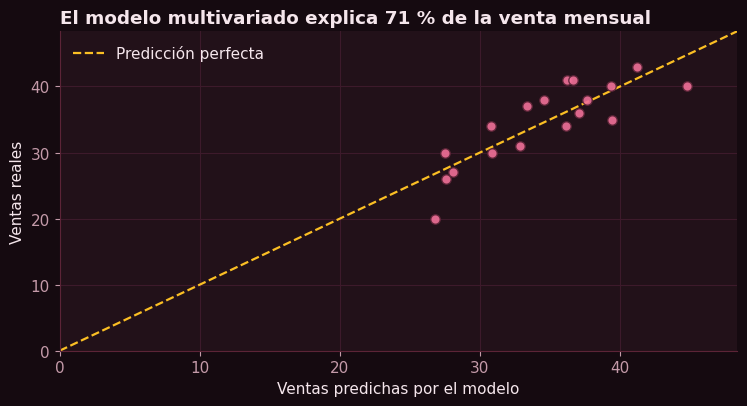

Única variable significativa: solicitudes de crédito aprobadas (p = 0.019).
El apalancamiento real está al final del embudo: crédito y cierre.


In [9]:
# Regresión lineal múltiple · Ventas ~ etapas del embudo (base funnel, 18 meses)
FEATS_M = ["Cita_Efectiva", "Prueba_Manejo", "SDC_Aprobada", "Formalizado"]
Nm = {"Cita_Efectiva": "Citas efectivas", "Prueba_Manejo": "Pruebas de manejo",
      "SDC_Aprobada": "Solicitudes de crédito aprobadas", "Formalizado": "Créditos formalizados"}
Xm = sm.add_constant(fu[FEATS_M]); m2 = sm.OLS(fu["Ventas"], Xm).fit()
print(f"R² = {m2.rsquared:.2f} · R² ajustado = {m2.rsquared_adj:.2f} · p global = {m2.f_pvalue:.4f} · n = {int(m2.nobs)} meses")

tab = pd.DataFrame({"Variable": [Nm[f] for f in FEATS_M], "Coeficiente": m2.params[FEATS_M].values,
                    "p-valor": m2.pvalues[FEATS_M].values}).round(4)
tab["Significativa (p<0.05)"] = np.where(tab["p-valor"] < .05, "Sí", "No")
display(tab)

fig, ax = nueva_fig(7.6, 4.2)
pred = m2.predict(Xm)
ax.scatter(pred, fu["Ventas"], s=46, color=ACC2, alpha=.9, edgecolors="#5c2437", zorder=3)
lims = [0, max(pred.max(), fu["Ventas"].max())*1.08]
ax.plot(lims, lims, color=AMB, lw=1.6, ls="--", label="Predicción perfecta")
ax.set_xlabel("Ventas predichas por el modelo"); ax.set_ylabel("Ventas reales")
ax.legend(frameon=False); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title("El modelo multivariado explica 71 % de la venta mensual", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Única variable significativa: solicitudes de crédito aprobadas (p = 0.019).")
print("El apalancamiento real está al final del embudo: crédito y cierre.")

**Regresión logística** *(exploratorio — 13 de 30 meses cumplieron objetivo)*: ¿qué distingue un mes que **sí cumple** su objetivo de uno que no?

Meses que cumplieron objetivo: 13 de 30
Matriz de confusión (9 meses de prueba):
[[4 1]
 [1 3]]
Accuracy 0.78 · Precisión 0.75 · Recall 0.75 · F1 0.75


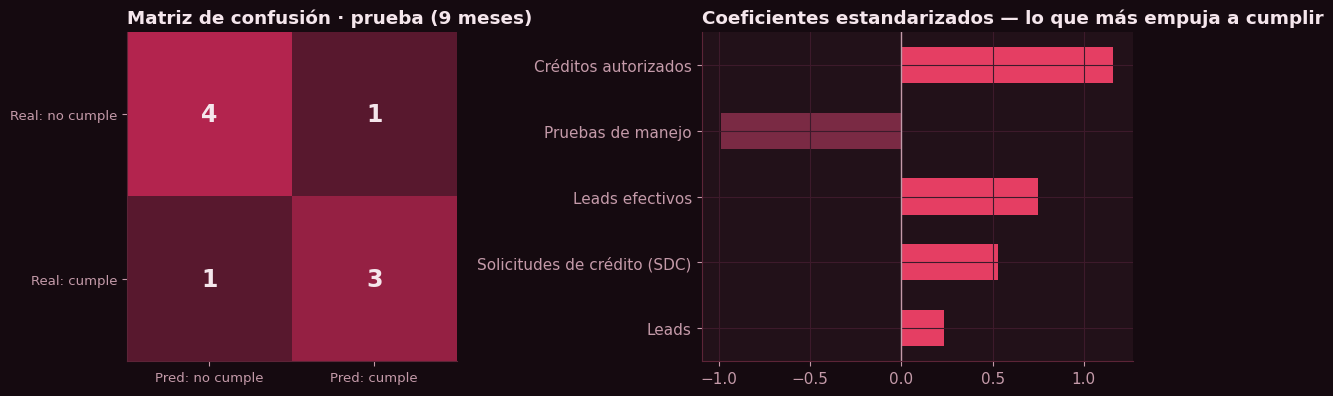

Lo que más empuja a cumplir: créditos autorizados y solicitudes (SDC).
⚠ Exploratorio: 30 meses totales, 9 de prueba. Nota: los coeficientes exactos del
prototipo (1.29 / 0.63 / 0.54 / 0.01 / −0.76) no se reproducen con los CSV del repo;
aquí se reportan los calculados desde la base actual. La conclusión es la misma.


In [10]:
# Clasificador: ¿el mes cumple su objetivo? (sí/no)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

FEATS_L = ["Autorizadas", "SDC", "Efectivos", "Leads", "PDM"]
NOMS_L = ["Créditos autorizados", "Solicitudes de crédito (SDC)", "Leads efectivos", "Leads", "Pruebas de manejo"]
X = res[FEATS_L].values.astype(float)
y = (res["Ventas Real"] >= res["Obj Ventas"]).astype(int).values
print(f"Meses que cumplieron objetivo: {y.sum()} de {len(y)}")

Xtr, Xte, ytr, yte = train_test_split(StandardScaler().fit_transform(X), y, test_size=0.3, random_state=58)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
yp = clf.predict(Xte)
cm = confusion_matrix(yte, yp)
print(f"Matriz de confusión (9 meses de prueba):\n{cm}")
print(f"Accuracy {accuracy_score(yte,yp):.2f} · Precisión {precision_score(yte,yp):.2f} · "
      f"Recall {recall_score(yte,yp):.2f} · F1 {f1_score(yte,yp):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.6, 4.1))
fig.patch.set_facecolor(BG)
for a in (a1, a2):
    a.set_facecolor(PANEL)
a1.imshow(cm, cmap=cmap_cm, vmin=0)
for i in range(2):
    for j in range(2):
        a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=17, fontweight="bold")
a1.set_xticks([0, 1]); a1.set_yticks([0, 1])
a1.set_xticklabels(["Pred: no cumple", "Pred: cumple"], fontsize=9.5)
a1.set_yticklabels(["Real: no cumple", "Real: cumple"], fontsize=9.5)
a1.grid(False); a1.set_title("Matriz de confusión · prueba (9 meses)", loc="left", fontweight="bold")

cf = pd.Series(clf.coef_[0], index=NOMS_L).sort_values(key=np.abs)
a2.barh(cf.index, cf.values, color=[ACC if v > 0 else "#7a2a44" for v in cf.values], height=.55)
a2.axvline(0, color=MUT, lw=1)
a2.set_title("Coeficientes estandarizados — lo que más empuja a cumplir", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Lo que más empuja a cumplir: créditos autorizados y solicitudes (SDC).")
print("⚠ Exploratorio: 30 meses totales, 9 de prueba. Nota: los coeficientes exactos del")
print("prototipo (1.29 / 0.63 / 0.54 / 0.01 / −0.76) no se reproducen con los CSV del repo;")
print("aquí se reportan los calculados desde la base actual. La conclusión es la misma.")

ANOVA multifactorial · Efectividad ~ Año × Trimestre (tipo I)
                  df     sum_sq   mean_sq       F  PR(>F)
C(Año)           1.0   171.2256  171.2256  1.7425  0.2066
C(Trim)          3.0  1568.8896  522.9632  5.3219  0.0107
C(Año):C(Trim)   3.0   154.7544   51.5848  0.5249  0.6718
Residual        15.0  1474.0000   98.2667     NaN     NaN


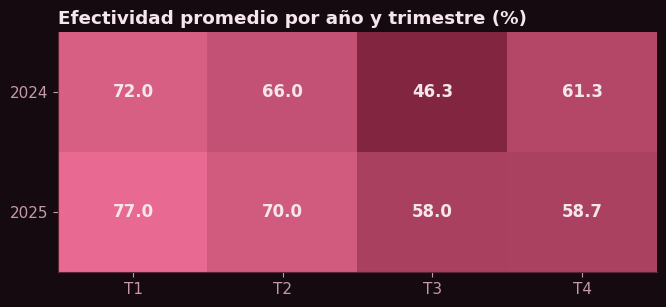

Trimestre sí es significativo (p = 0.011): el T1 es el más fuerte y el T3 el más débil.
Año y la interacción no lo son. Se excluye 2026 porque aún no tiene datos del T3 y T4.


In [11]:
# ANOVA multifactorial · Efectividad ~ Año + Trimestre (2024-2025, base leads reales)
d = lr[lr["Año"].isin([2024, 2025])].copy()
d["Trim"] = "T"+(((d["Mes_Num"]-1)//3)+1).astype(int).astype(str)
hm = d.pivot_table(index="Año", columns="Trim", values="Efectividad_Leads", aggfunc="mean").round(1)

mod2 = sm.OLS.from_formula("Efectividad_Leads ~ C(Año)*C(Trim)", data=d).fit()
an2 = sm.stats.anova_lm(mod2, typ=1)   # suma de cuadrados secuencial (tipo I)
print("ANOVA multifactorial · Efectividad ~ Año × Trimestre (tipo I)")
print(an2.round(4).to_string())

fig, ax = nueva_fig(6.8, 3.2)
ax.imshow(hm.values, cmap=cmap_hm, vmin=40, vmax=80, aspect="auto")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i,j]:.1f}", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels(hm.columns)
ax.set_yticks(range(2)); ax.set_yticklabels(hm.index)
ax.grid(False); ax.set_title("Efectividad promedio por año y trimestre (%)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Trimestre sí es significativo (p = 0.011): el T1 es el más fuerte y el T3 el más débil.")
print("Año y la interacción no lo son. Se excluye 2026 porque aún no tiene datos del T3 y T4.")

---

## Cierre — el hallazgo que sostiene la propuesta

1. **Vista 1:** el embudo pierde la mayoría de oportunidades en **Contacto → Cita (32 %)**; la efectividad mejora, pero lento y con meses por debajo de 55 %.
2. **Vista 2:** de 208 leads de plaza, **37 % quedó solo en Contactado** y apenas 4 % compró; además **~1 de cada 10 leads llega ilocalizable** por mala captura (el ANOVA confirma que varía por año).
3. **Vista 3:** lo que mueve la venta no es el volumen de leads (R² = 0.25) sino el **fondo del embudo** (solicitudes y créditos, R² = 0.71); hay patrón estacional por trimestre.

Con tres fugas identificadas y medibles, la propuesta de la plataforma analítica (tablero + alertas de captura + seguimiento del embudo) ataca causas concretas, no síntomas.

*Dashboard replicado en notebook por el Equipo 4 · base de cálculo: CSV del repo `GAC-Auditoria-Analitica`.*